# Persian Card OCR — نسخه V2

**نسخه اصلاح‌شده عکس‌های بدون فضای اطراف کارت: `tight-crop-v2`**

در منوی Kernel، گزینه Restart Kernel and Run All Cells را اجرا کنید. نشان نسخه باید در خروجی سلول‌های ۴ و ۵ دیده شود.

# کارت ملی فارسی: دریافت عکس ← تشخیص گوشه‌ها ← صاف‌کردن ← OCR با Hezar

نسخه محلی پروژه برای **Jupyter در محیط .venv همین پروژه**. سلول‌ها را از بالا به پایین اجرا کنید.
به هیچ سلول یا متغیر نوت‌بوک قبلی نیاز ندارد. برای هر عکس، محل کارت و دو جهت ممکن به‌صورت خودکار بررسی می‌شود.

**مدل‌ها:** وزن رسمی DocAligner FastViT-T8 برای چهار گوشه، Hezar CRAFT برای محل متن و
Hezar CRNN فارسی برای خواندن متن. DocAligner مستقیماً با ONNX Runtime اجرا می‌شود تا محدودیت نصب
بسته اصلی آن در Python جدید مانع اجرا نشود. رمزگشایی heatmap در این دفتر با OpenCV بازپیاده‌سازی شده
و دقیقاً معادل تمام جزئیات کتابخانه اصلی نیست.

**خروجی:** عکس مرز پیشنهادی، کارت صاف‌شده، کارت با جهت منتخب، برش متن‌ها، `text.txt`، `result.json`،
جدول CSV نواحی و ZIP نتایج. نتیجه، متن OCR است؛ نام‌گذاری شش فیلد هویتی در این نسخه پیاده نشده است.

این دفتر برای عکس یک کارت طراحی شده است. معیارهای هندسی فقط کادر پیشنهادی را کنترل می‌کنند، نه هویت شیء.
کارت ناقص، گوشه پوشیده، انعکاس یا تاری ممکن است نتیجه اشتباه بدهد. وضعیت `ocr_candidate` تضمین صحت نیست.
جهت با امتیاز ابتکاری OCR انتخاب می‌شود؛ `orientation_uncertain` یعنی متن ذخیره شده ولی جهت نیاز به بررسی دارد.
اطلاعات CSV هرگز برای انتخاب کادر، جهت یا تصحیح متن استفاده نمی‌شود.

دانلود اول به اینترنت نیاز دارد. در Kaggle اینترنت را فعال کنید. GPU برای Hezar اختیاری است؛
DocAligner در این دفتر روی CPU اجرا می‌شود. روی CPU آزمایش هر کارت ممکن است چند دقیقه طول بکشد.


## ۱. محیط پروژه
کرنل **Persian Card OCR (.venv)** را انتخاب کنید. نصب وابستگی‌ها در محیط پروژه انجام شده است. مسیر مفسر زیر باید داخل همین پروژه باشد.


In [1]:
# وابستگی‌ها در .venv پروژه نصب شده‌اند.
import sys
print(sys.executable)


/Users/neginnoori/Documents/Codex/Persian_OCR_IDCard/.venv/bin/python


## ۲. تنظیمات
برای شروع فقط یک کارت اجرا می‌شود. پردازش گروهی و آپلود اختیاری هستند؛ Run all منتظر آپلود نمی‌ماند.


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import json
import shutil
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from IPython.display import display, FileLink
from tqdm.auto import tqdm

DATASET_SLUG = 'kibordevents/iranian-national-id-card-dataset'
DATASET_ROOT_OVERRIDE = None  # برای داده موجود: Path('/مسیر/دیتاست')
DEMO_IMAGE_ID = '354'
DOCALIGNER_VARIANT = 'fastvit_t8'  # جایگزین‌ها: fastvit_sa24 یا lcnet100
RUN_DATASET_DEMO = False  # برای شروع فقط عکس خودت؛ برای نمونه Kaggle مقدار True
RUN_BATCH = False
BATCH_IDS = ['1861', '1334', '906', '1290', '820', '868', '379', '1210', '95']
RUN_UPLOAD = False  # فقط در Colab، برای آپلود عکس شخصی True کنید.
USER_IMAGE_PATH = '/Users/neginnoori/Downloads/20231030_131723_599212866.jpg'  # یا مستقیماً مسیر عکس دلخواه را وارد کنید.
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').is_file() and (p/'src/persian_card_ocr').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Notebook را از پوشه پروژه اجرا کنید.')
base = PROJECT_ROOT
RUN_DIR = base/'card_ocr_outputs'/datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = base/'models'
versions = {'python': platform.python_version(), 'device': DEVICE}
for name in ['hezar', 'torch', 'torchvision', 'onnxruntime', 'numpy', 'Pillow', 'kagglehub']:
    try:
        versions[name] = metadata.version(name)
    except metadata.PackageNotFoundError:
        versions[name] = None
(RUN_DIR/'environment.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')
print(versions)
print('Output:', RUN_DIR)


Matplotlib is building the font cache; this may take a moment.


{'python': '3.11.11', 'device': 'cpu', 'hezar': '1.0.0', 'torch': '2.14.1', 'torchvision': '0.29.1', 'onnxruntime': '1.31.1', 'numpy': '2.4.6', 'Pillow': '13.0.0', 'kagglehub': '1.0.3'}
Output: /Users/neginnoori/Documents/Codex/Persian_OCR_IDCard/card_ocr_outputs/20261027_172309_308038


/Users/neginnoori/Documents/Codex/Persian_OCR_IDCard/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## ۳. دریافت دیتاست از Kaggle و ساخت مسیرهای واقعی
اگر دیتاست قبلاً به Kaggle Notebook وصل شده باشد، همان فایل‌ها استفاده می‌شوند؛ در غیر این صورت
`kagglehub` دانلود می‌کند. در صورت درخواست ورود Kaggle، یک بار `kagglehub.login()` را در سلول جدا اجرا کنید.
مسیرها به Colab یا Kaggle قبلی وابسته نیستند. فایل‌های بدون شناسه، مثل `sample1.jpg`، در نمایه شماره‌دار نیستند.


In [3]:
if RUN_DATASET_DEMO or RUN_BATCH:
    import kagglehub

    if DATASET_ROOT_OVERRIDE is not None:
        DATASET_ROOT = Path(DATASET_ROOT_OVERRIDE).expanduser().resolve()
    else:
        attached = Path('/kaggle/input/iranian-national-id-card-dataset')
        DATASET_ROOT = attached if attached.is_dir() else Path(kagglehub.dataset_download(DATASET_SLUG))
    if not DATASET_ROOT.is_dir():
        raise FileNotFoundError(DATASET_ROOT)

    image_index = {}
    for path in DATASET_ROOT.rglob('*'):
        if path.is_file() and path.suffix.lower() in {'.jpg', '.jpeg', '.png', '.webp'} and path.stem.isdigit():
            key = str(int(path.stem))
            if key in image_index:
                raise RuntimeError(f'مسیر مبهم برای شناسه {key}: {image_index[key]}, {path}')
            image_index[key] = path
    if not image_index:
        raise RuntimeError('هیچ تصویر شماره‌دار پیدا نشد؛ ریشه دیتاست را بررسی کنید.')

    # جدول صرفاً برای مشاهده است و وارد تابع OCR نمی‌شود.
    csv_candidates = sorted(DATASET_ROOT.rglob('*.csv'))
    labels = None
    for path in csv_candidates:
        table = pd.read_csv(path, dtype=str, keep_default_na=False)
        if {'id', 'national_id', 'first_name'}.issubset(table.columns):
            labels = table
            break
    print('Dataset root:', DATASET_ROOT)
    print('Number of indexed images:', len(image_index))
    if labels is not None:
        print('Label rows:', len(labels))

    def image_path(image_id):
        key = str(int(image_id))
        if key not in image_index:
            raise FileNotFoundError(f'شناسه {key} در {DATASET_ROOT} پیدا نشد.')
        return image_index[key]

    print('Demo path:', image_path(DEMO_IMAGE_ID))

else:
    print("Kaggle demo skipped; processing local image only.")


Kaggle demo skipped; processing local image only.


## ۴. توابع مستقل پردازش
این سلول همه توابع را تعریف می‌کند. آرایه چهار گوشه در مختصات عکس اصلی است.
تصحیح EXIF قبل از تشخیص انجام می‌شود. CRAFT روی نسخه حداکثر ۱۲۸۰ پیکسل اجرا می‌شود؛
با نسبت داخلی دقیقاً یک، خطای مقیاس مختصات Hezar 1.0.0 دور زده می‌شود و برش‌ها از کارت با وضوح بالاتر گرفته می‌شوند.
حاشیه برش‌ها برای همه یکسان است: افقی ۲۰٪ و عمودی ۳۰٪ ارتفاع ناحیه، حداقل ۸ پیکسل.

برای عکس‌هایی که کارت تمام کادر را پر کرده، پس از شکست اولیه یک حاشیه موقت ۱۵٪ اضافه و تشخیص تکرار می‌شود. مختصات به عکس اصلی برمی‌گردند؛ حاشیه مصنوعی وارد OCR نمی‌شود. پس از تغییر کد، این سلول و سلول بارگذاری موتور را دوباره اجرا کنید.


In [4]:
import importlib
import sys
sys.path.insert(0, str(PROJECT_ROOT/'src'))
import persian_card_ocr.pipeline as pipeline
pipeline = importlib.reload(pipeline)
CardOCR, read_rgb = pipeline.CardOCR, pipeline.read_rgb
assert CardOCR.REVISION == 'tight-crop-v2', 'Wrong pipeline version loaded'
print('Pipeline revision:', CardOCR.REVISION)
print('Source file:', pipeline.__file__)


Pipeline revision: tight-crop-v2
Source file: /Users/neginnoori/Documents/Codex/Persian_OCR_IDCard/src/persian_card_ocr/pipeline.py


## ۵. بارگذاری وزن‌ها
اولین اجرا وزن رسمی DocAligner را از Google Drive سازنده و دو مدل Hezar را از Hugging Face دانلود می‌کند.
اگر Google Drive محدود شد، فایل مدل را دستی در `MODEL_DIR` با نام دقیق درج‌شده در `CardOCR.WEIGHTS` قرار دهید.
هش وزن و نسخه‌های نصب‌شده برای پیگیری اجرای واقعی ذخیره می‌شوند.


In [5]:
engine = CardOCR(MODEL_DIR, variant=DOCALIGNER_VARIANT, device=DEVICE)
print('DocAligner:', engine.variant)
print('ONNX providers:', engine.session.get_providers())
print('Weights SHA256:', engine.model_sha256)
print('Hezar device:', DEVICE)
print('Engine revision:', engine.REVISION)


W1027 20:53:12.065000 50238 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


DocAligner: fastvit_t8
ONNX providers: ['CPUExecutionProvider']
Weights SHA256: 950070fd4a46e25d46db7c35d0ed77612d9063f70d4543c7c504f0da6a943a89
Hezar device: cpu
Engine revision: tight-crop-v2


## ۶. نمایش و ذخیره نتایج
کادر سبز پیشنهاد مدل است. متن خروجی خام نگه داشته می‌شود؛ نسخه نرمال‌شده هر ناحیه هم در JSON و CSV موجود است.


In [6]:
def show_result(result, folder):
    folder = Path(folder)
    files = [('boundary.jpg', 'Detected boundary'), ('oriented.png', 'Selected orientation'),
             ('text_boxes.png', 'Text regions')]
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, (name, title) in zip(axes, files):
        path = folder/name
        if path.is_file() and ((name == 'boundary.jpg' and result.get('corners') is not None) or (name != 'boundary.jpg' and result.get('regions'))):
            with Image.open(path) as im:
                ax.imshow(im)
        else:
            ax.text(.5, .5, result['status'], ha='center', va='center')
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Status:', result['status'])
    print('Seconds:', result['elapsed_seconds'])
    if 'error' in result:
        print('Error:', result['error'])
    print('\nOCR text:\n')
    print(result['text'] or '(متنی به دست نیامد)')
    rows = []
    for i, region in enumerate(result['regions']):
        rows.append({'region_id': i, 'x1': region['box'][0], 'y1': region['box'][1],
                     'x2': region['box'][2], 'y2': region['box'][3],
                     'text_raw': region['text_raw'], 'text_normalized': region['text']})
    table = pd.DataFrame(rows, columns=['region_id', 'x1', 'y1', 'x2', 'y2', 'text_raw', 'text_normalized'])
    table.to_csv(folder/'regions.csv', index=False, encoding='utf-8-sig')
    display(table)

def run_one(source, name):
    global engine
    # Reload before every image, then update the existing model instance.
    # Model weights are reused; obsolete locate() methods cannot remain active.
    import importlib
    import persian_card_ocr.pipeline as live_pipeline
    live_pipeline = importlib.reload(live_pipeline)
    assert live_pipeline.CardOCR.REVISION == 'tight-crop-v2'
    engine.__class__ = live_pipeline.CardOCR
    print('Running pipeline:', engine.REVISION)
    folder = RUN_DIR/(name+'_'+datetime.now(timezone.utc).strftime('%H%M%S_%f'))
    result = engine.process(source, folder)
    print('Location attempts:', result.get('location_attempts', []))
    show_result(result, folder)
    return result


## ۷. اجرای کامل روی یک کارت دیتاست
از همین سلول می‌توانید شناسه را عوض کنید. انتخاب کادر و جهت هیچ ورودی دستی ندارد.

در V2 پیش‌فرض `RUN_DATASET_DEMO=False` است تا برای آزمایش عکس محلی نیازی به دریافت دیتاست نباشد.


In [7]:
if RUN_DATASET_DEMO:
    demo_result = run_one(image_path(DEMO_IMAGE_ID), f'card_{DEMO_IMAGE_ID}')
else:
    print('Dataset demo disabled; local image runs in section 9.')


Dataset demo disabled; local image runs in section 9.


## ۸. پردازش گروهی اختیاری
برای اجرا `RUN_BATCH=True` بگذارید و سلول تنظیمات و این سلول را اجرا کنید.
این شناسه‌ها نمونه‌های توسعه‌اند؛ از نتیجه آن‌ها دقت مجموعه آزمون نتیجه نگیرید.
خطای هر کارت در گزارش ثبت می‌شود و کارت بعدی پردازش می‌شود. هر کارت پوشه مستقل دارد.


In [8]:
batch_results = []
if RUN_BATCH:
    for image_id in tqdm(BATCH_IDS, desc='Cards'):
        print('Processing:', image_id, flush=True)
        try:
            source = image_path(image_id)
            result = engine.process(source, RUN_DIR/f'card_{image_id}')
        except Exception as exc:
            result = {'status': 'input_error', 'text': '', 'regions': [],
                      'error': f'{type(exc).__name__}: {exc}', 'elapsed_seconds': 0}
        batch_results.append({'image_id': image_id, 'status': result['status'],
                              'region_count': len(result['regions']),
                              'elapsed_seconds': result['elapsed_seconds'],
                              'error': result.get('error', ''), 'text': result['text']})
        pd.DataFrame(batch_results).to_csv(RUN_DIR/'batch_summary.csv', index=False, encoding='utf-8-sig')
        print('Status:', result['status'], flush=True)
    display(pd.DataFrame(batch_results).drop(columns='text'))
else:
    print('Batch disabled. Set RUN_BATCH=True to run.')


Batch disabled. Set RUN_BATCH=True to run.


## ۹. عکس دلخواه یا آپلود از کامپیوتر
در Jupyter و Kaggle، مسیر را در `USER_IMAGE_PATH` تنظیم کنید.
در Colab می‌توانید `RUN_UPLOAD=True` بگذارید و این سلول را اجرا کنید.
پس از بارگذاری موتور، تابع عمومی فقط عکس و مسیر خروجی می‌گیرد:
`result = engine.process('/path/card.jpg', RUN_DIR/'my_card')`.


Running pipeline: tight-crop-v2
  OCR orientation: 0


  OCR orientation: 180


Location attempts: [{'padding_pixels': 0, 'status': 'corners_not_found', 'heatmap_peaks': [0.38567471504211426, 0.02567926049232483, 0.028157591819763184, 0.13053041696548462]}, {'padding_pixels': 120, 'status': 'geometry_candidate', 'heatmap_peaks': [0.918624758720398, 0.8654839992523193, 0.8844578266143799, 0.9218484163284302]}]


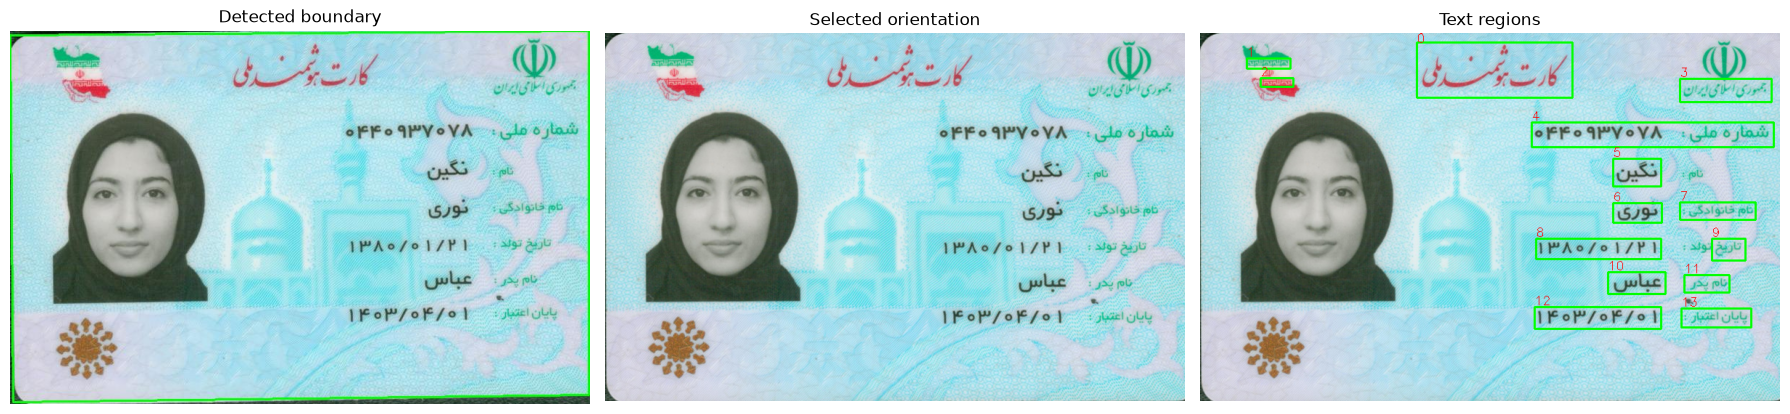

Status: ocr_candidate
Seconds: 2.496

OCR text:

گک
اتس
اا
ور 
شماره لی ۰۴۴۰۹۳۷۰۷۸
نگین
نناادک نوری
ر ۱۳۸۰/۰۱/۲۱
نامدر عباس
پابالاتار ۱۴۰۳/۰۴/۰۱


,region_id,x1,y1,x2,y2,text_raw,text_normalized
0,0,298,12,512,88,اتس,اتس
1,1,64,34,124,48,گک,گک
2,2,83,61,128,73,اا,اا
3,3,660,62,786,94,ور,ور
4,4,456,122,789,156,شماره لی ۰۴۴۰۹۳۷۰۷۸,شماره لی 0440937078
5,5,568,172,634,210,نگین,نگین
6,6,568,233,635,260,نوری,نوری
7,7,660,232,764,256,نناادک,نناادک
8,8,462,282,634,310,۱۳۸۰/۰۱/۲۱,1380/01/21
9,9,704,282,750,312,ر,ر


In [9]:
if USER_IMAGE_PATH is not None:
    user_result = run_one(Path(USER_IMAGE_PATH), 'user_image')
if RUN_UPLOAD:
    try:
        from google.colab import files
    except ImportError:
        raise RuntimeError('آپلود تعاملی این سلول مخصوص Colab است؛ USER_IMAGE_PATH را تنظیم کنید.')
    import io
    uploaded = files.upload()
    for index, (filename, content) in enumerate(uploaded.items()):
        with Image.open(io.BytesIO(content)) as im:
            # read_rgb handles EXIF while the input buffer is still open.
            user_result = run_one(read_rgb(im), f'upload_{index:03d}')
if USER_IMAGE_PATH is None and not RUN_UPLOAD:
    print('Optional input disabled.')


## ۱۰. خروجی نهایی و دریافت ZIP
`text.txt` متن قابل استفاده است؛ `result.json` شامل متن، مختصات، جهت و وضعیت است.
همه نواحی و برش‌ها برای بررسی خطا نگهداری می‌شوند. نام `candidate` یعنی نتیجه پیشنهادی است؛
نباید تعداد آن را به‌عنوان تعداد کارت‌های صحیح گزارش کرد.


In [10]:
zip_path = Path(shutil.make_archive(str(RUN_DIR), 'zip', root_dir=RUN_DIR))
print('Results:', RUN_DIR)
print('ZIP:', zip_path)
try:
    from google.colab import files
    print('برای دانلود ZIP، این دستور را در سلول بعد اجرا کنید:')
    print(f'files.download({str(zip_path)!r})')
except ImportError:
    display(FileLink(str(zip_path)))


Results: /Users/neginnoori/Documents/Codex/Persian_OCR_IDCard/card_ocr_outputs/20261027_172309_308038
ZIP: /Users/neginnoori/Documents/Codex/Persian_OCR_IDCard/card_ocr_outputs/20261027_172309_308038.zip


/Users/neginnoori/Documents/Codex/Persian_OCR_IDCard/card_ocr_outputs/20261027_172309_308038.zip

## منابع و محدوده اعتبار

- [DocAligner: مخزن و وزن‌های رسمی](https://github.com/DocsaidLab/DocAligner)
- [پیش‌پردازش، تنظیم وزن‌ها و heatmap رسمی](https://github.com/DocsaidLab/DocAligner/blob/main/docaligner/heatmap_reg/infer.py)
- [Hezar CRAFT](https://huggingface.co/hezarai/CRAFT)
- [Hezar CRNN فارسی](https://huggingface.co/hezarai/crnn-base-fa-v2)
- [دیتاست Kaggle](https://www.kaggle.com/datasets/kibordevents/iranian-national-id-card-dataset)

ساخته‌شده در ۲۰۲۶-۱۰-۲۷. نسخه Hezar ثابت است؛ دیگر وابستگی‌ها در اجرای واقعی ثبت می‌شوند.
تست ساختار و توابع از ارزیابی دقت واقعی مدل جداست. خروجی‌های این دفتر خالی‌اند تا نتایج قدیمی به اجرای شما نسبت داده نشوند.
مدل‌های آماده هنوز باید روی تصاویر شما ارزیابی شوند. اگر مدل مرز اشتباه بدهد، OCR خوب آن خطا را جبران نمی‌کند.
